<a href="https://colab.research.google.com/github/YaseenRamzyy/ML-Assignment-2/blob/main/ML_Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Introduction to Machine Learning — Assignment 2**

## **0. Imports and reproducibility**

We use NumPy for the implementations, pandas for readable result tables, and matplotlib for plots. Scikit-learn is used only for loading the required datasets, splitting the data, and the explicit reference comparisons requested in the assignment.

In [25]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits, load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    confusion_matrix as sklearn_confusion_matrix,
    precision_recall_fscore_support
)

np.set_printoptions(precision=6, suppress=True)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("NumPy version:", np.__version__)
print("All randomness in this notebook uses random_state / default_rng seed 42.")

NumPy version: 2.4.6
All randomness in this notebook uses random_state / default_rng seed 42.


## **Part A — Data and toolkit**

### **Task 1. Load the four datasets and apply the required 60 / 20 / 20 split**

The assignment specifies:
1. Split 20% into the test set using `random_state=42`.
2. Split 25% of the remaining 80% into validation (which is 20% of the full dataset).
3. Use stratification for classification datasets, but not for Diabetes regression.

Dataset-specific preparation:
- Diabetes: `load_diabetes(scaled=False)`; keep the target in its original units.
- Breast Cancer: flip the labels so malignant = 1 and benign = 0.
- Digits: divide pixel values by 16; do not standardize them.
- Iris: use the original four features and three classes.

In [26]:
# Load datasets exactly as described in the assignment

diabetes = load_diabetes(scaled=False)
breast = load_breast_cancer()
digits = load_digits()
iris = load_iris()

datasets = {}

# Diabetes: regression, so stratify=None

datasets["Diabetes"] = {
    "X": diabetes.data.astype(float),
    "y": diabetes.target.astype(float),
    "feature_names": list(diabetes.feature_names),
    "task": "regression"
}

# Breast Cancer: malignant must be the positive class (1)

datasets["Breast cancer"] = {
    "X": breast.data.astype(float),
    "y": (1 - breast.target).astype(int),
    "feature_names": list(breast.feature_names),
    "task": "classification"
}

# Digits: scale pixel intensities to [0, 1] by dividing by 16

datasets["Digits"] = {
    "X": digits.data.astype(float) / 16.0,
    "y": digits.target.astype(int),
    "feature_names": [f"pixel_{i}" for i in range(digits.data.shape[1])],
    "task": "classification"
}

datasets["Iris"] = {
    "X": iris.data.astype(float),
    "y": iris.target.astype(int),
    "feature_names": list(iris.feature_names),
    "task": "classification"
}

# Apply the exact two-step split protocol

splits = {}
for name, data in datasets.items():
    X, y = data["X"], data["y"]
    stratify_all = y if data["task"] == "classification" else None

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=stratify_all
    )

    stratify_train = y_train if data["task"] == "classification" else None
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=42,
        stratify=stratify_train
    )

    splits[name] = {
        "X_train": X_train, "X_val": X_val, "X_test": X_test,
        "y_train": y_train, "y_val": y_val, "y_test": y_test,
        "feature_names": data["feature_names"],
        "task": data["task"]
    }

# Required split sizes

expected_sizes = {
    "Diabetes": (264, 89, 89, 442),
    "Breast cancer": (341, 114, 114, 569),
    "Digits": (1077, 360, 360, 1797),
    "Iris": (90, 30, 30, 150)
}

rows = []

for name, sp in splits.items():

    sizes = tuple(len(sp[k]) for k in ["y_train", "y_val", "y_test"])
    total = sum(sizes)
    rows.append([name, *sizes, total, expected_sizes[name]])
    assert sizes + (total,) == expected_sizes[name], f"Unexpected split sizes for {name}"

split_table = pd.DataFrame(
    [[r[0], r[1], r[2], r[3], r[4]] for r in rows],
    columns=["Dataset", "Train", "Validation", "Test", "Total"]
)

display(split_table)
print("All split sizes match the assignment.")

,Dataset,Train,Validation,Test,Total
0,Diabetes,264,89,89,442
1,Breast cancer,341,114,114,569
2,Digits,1077,360,360,1797
3,Iris,90,30,30,150


All split sizes match the assignment.


### Task 1 — Classification class counts

The next table prints the number of examples from every class in each classification split. Stratification keeps the class proportions approximately the same across training, validation, and test sets.

In [27]:
for name in ["Breast cancer", "Digits", "Iris"]:
    sp = splits[name]
    print(f"\n{name}")
    classes = np.unique(datasets[name]["y"])

    count_table = pd.DataFrame({
        "Train": [np.sum(sp["y_train"] == c) for c in classes],
        "Validation": [np.sum(sp["y_val"] == c) for c in classes],
        "Test": [np.sum(sp["y_test"] == c) for c in classes]
    }, index=classes)

    count_table.index.name = "Class"
    display(count_table)


Breast cancer


,Train,Validation,Test
Class,,,
0,214,71,72
1,127,43,42



Digits


,Train,Validation,Test
Class,,,
0,106,36,36
1,109,37,36
2,107,35,35
3,109,37,37
4,109,36,36
5,109,36,37
6,109,36,36
7,107,36,36
8,104,35,35



Iris


,Train,Validation,Test
Class,,,
0,30,10,10
1,30,10,10
2,30,10,10


### **Task 2. Standardizer and bias-column function**
For each feature, the standardizer stores the training mean and standard deviation:
\[
z = \frac{x-\mu_{train}}{\sigma_{train}}.
\]

If a training feature has zero standard deviation, we replace it with 1 to avoid division by zero. The same training statistics are then applied to validation and test data.

We also implement `add_bias(X)`, which adds a first column of ones. This represents the intercept (bias) in the weight vector.

In [28]:
class Standardizer:
    def fit(self, X):
        # Learn statistics from training rows only.
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        # Reuse the training statistics without refitting.
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def add_bias(X):
    # Add a leading column of ones for the intercept.
    return np.column_stack((np.ones(X.shape[0]), X))


# Fit standardizers for all four datasets, but do not standardize Digits
# because the assignment explicitly says to keep pixels divided by 16.
standardized_splits = {}
standardizers = {}

for name, sp in splits.items():
    if name == "Digits":
        standardized_splits[name] = {
            key: sp[key].copy() for key in
            ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
        }
    else:
        scaler = Standardizer().fit(sp["X_train"])
        standardizers[name] = scaler
        standardized_splits[name] = {
            "X_train": scaler.transform(sp["X_train"]),
            "X_val": scaler.transform(sp["X_val"]),
            "X_test": scaler.transform(sp["X_test"]),
            "y_train": sp["y_train"].copy(),
            "y_val": sp["y_val"].copy(),
            "y_test": sp["y_test"].copy()
        }

# Verify standardized training columns have mean 0 and standard deviation 1.
for name in ["Diabetes", "Breast cancer", "Iris"]:
    Xtr = standardized_splits[name]["X_train"]
    means = np.mean(Xtr, axis=0)
    stds = np.std(Xtr, axis=0)
    print(name, "| maximum absolute training mean:", np.max(np.abs(means)),
          "| minimum / maximum training std:", np.min(stds), np.max(stds))
    assert np.max(np.abs(means)) < 1e-9
    assert np.allclose(stds, 1.0, atol=1e-12)

print("\nValidation and test means are generally not zero because their rows were not used to fit the standardizer.")

Diabetes | maximum absolute training mean: 2.2372676102294822e-15 | minimum / maximum training std: 0.9999999999999979 1.0000000000000004
Breast cancer | maximum absolute training mean: 5.108979384873301e-15 | minimum / maximum training std: 0.9999999999999993 1.0000000000000009
Iris | maximum absolute training mean: 1.2927930331190711e-15 | minimum / maximum training std: 0.9999999999999996 1.0

Validation and test means are generally not zero because their rows were not used to fit the standardizer.


**Task 2 — Why training-only statistics matter (two sentences).**

The mean and standard deviation must be calculated from training rows only so that validation and test data remain unseen when the model is being prepared and evaluated. If we calculate these statistics using all rows, information about the test distribution leaks into training, making the final test result less independent and potentially misleading.

### **Task 3. Implement regression and classification metrics**

We implement:
- MSE, RMSE, and R² for regression.
- Accuracy and a confusion matrix for classification.
- Per-class precision, recall, and F1, plus macro averages.

For the confusion matrix, rows are the true classes and columns are predicted classes. **Precision is defined as 0 when a class is never predicted**, as required.

In [29]:
def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))


def r2(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1.0 - ss_res / ss_tot


def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def confusion_matrix(y_true, y_pred, K):

    # Rows = true class, columns = predicted class
    cm = np.zeros((K, K), dtype=int)
    for true_label, pred_label in zip(y_true, y_pred):
        cm[int(true_label), int(pred_label)] += 1
    return cm


def classification_metrics_from_cm(cm):
    cm = np.asarray(cm)
    true_positive = np.diag(cm)
    predicted_count = np.sum(cm, axis=0)
    actual_count = np.sum(cm, axis=1)

    # Required convention: precision = 0 if a class is never predicted
    precision = np.divide(
        true_positive, predicted_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=predicted_count != 0
    )
    recall = np.divide(
        true_positive, actual_count,
        out=np.zeros_like(true_positive, dtype=float),
        where=actual_count != 0
    )
    f1 = np.divide(
        2 * precision * recall, precision + recall,
        out=np.zeros_like(precision, dtype=float),
        where=(precision + recall) != 0
    )

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }


print("Metric functions are ready.")

Metric functions are ready.


#### **Task 3 verification against scikit-learn**

We generate 500 random true and predicted labels with four classes. Every metric is compared against the corresponding scikit-learn metric, and the absolute differences must be no larger than $ 10^{-12} $.

In [30]:
from sklearn.metrics import (
    mean_squared_error as sk_mse,
    mean_absolute_error,
    r2_score as sk_r2,
    accuracy_score as sk_accuracy,
    confusion_matrix as sk_cm
)

check_rng = np.random.default_rng(42)
N_check, K_check = 500, 4
y_true_check = check_rng.integers(0, K_check, size=N_check)
y_pred_check = check_rng.integers(0, K_check, size=N_check)

# Regression metric checks on random continuous values
y_reg = check_rng.normal(size=500)
y_reg_pred = y_reg + check_rng.normal(scale=0.5, size=500)

assert abs(mse(y_reg, y_reg_pred) - sk_mse(y_reg, y_reg_pred)) < 1e-12
assert abs(rmse(y_reg, y_reg_pred) - np.sqrt(sk_mse(y_reg, y_reg_pred))) < 1e-12
assert abs(r2(y_reg, y_reg_pred) - sk_r2(y_reg, y_reg_pred)) < 1e-12

# Classification metric checks
cm_ours = confusion_matrix(y_true_check, y_pred_check, K_check)
cm_sklearn = sk_cm(y_true_check, y_pred_check, labels=np.arange(K_check))
assert np.array_equal(cm_ours, cm_sklearn)
assert abs(accuracy(y_true_check, y_pred_check) -
           sk_accuracy(y_true_check, y_pred_check)) < 1e-12

ours = classification_metrics_from_cm(cm_ours)
sk_precision, sk_recall, sk_f1, _ = precision_recall_fscore_support(
    y_true_check, y_pred_check, labels=np.arange(K_check),
    zero_division=0
)

assert np.max(np.abs(ours["precision"] - sk_precision)) < 1e-12
assert np.max(np.abs(ours["recall"] - sk_recall)) < 1e-12
assert np.max(np.abs(ours["f1"] - sk_f1)) < 1e-12
assert abs(ours["macro_precision"] - np.mean(sk_precision)) < 1e-12
assert abs(ours["macro_recall"] - np.mean(sk_recall)) < 1e-12
assert abs(ours["macro_f1"] - np.mean(sk_f1)) < 1e-12

print("All Task 3 checks passed: differences are below 1e-12.")
print("Our confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(cm_ours))

All Task 3 checks passed: differences are below 1e-12.
Our confusion matrix (rows=true, columns=predicted):


,0,1,2,3
0,34,25,33,30
1,29,34,35,36
2,31,20,33,35
3,37,25,36,27


### Task 4. Numerical gradient checker

The gradient checker uses central differences:
$$
\
g_i^{num}=\frac{f(w+\epsilon e_i)-f(w-\epsilon e_i)}{2\epsilon}.
\
$$

It returns the relative error between the analytic and numerical gradients. The assignment asks for $ \epsilon=10^{-5} $ generally and $ 10^{-6} $ for hinge losses. For this task we implement the general checker; later tasks can pass a different epsilon when needed.

In [31]:
def grad_check(f, grad, w, epsilon=1e-5):
    w = np.asarray(w, dtype=float)
    numerical = np.zeros_like(w)

    for i in range(w.size):
        w_plus = w.copy()
        w_minus = w.copy()
        w_plus.flat[i] += epsilon
        w_minus.flat[i] -= epsilon
        numerical.flat[i] = (f(w_plus) - f(w_minus)) / (2 * epsilon)

    analytic = np.asarray(grad(w), dtype=float)
    numerator = np.linalg.norm(analytic - numerical)
    denominator = max(np.linalg.norm(analytic), np.linalg.norm(numerical), 1e-12)
    return numerator / denominator


# Small demonstration using f(w) = sum(w_i^2), gradient = 2w
w_demo = np.random.default_rng(42).normal(0, 0.1, size=8)
demo_error = grad_check(
    lambda w: np.sum(w ** 2),
    lambda w: 2 * w,
    w_demo
)
print("Demonstration relative gradient error:", demo_error)
assert demo_error < 1e-6

Demonstration relative gradient error: 2.4145997498264953e-12


---

# Part B — Linear Regression

**Dataset:** Diabetes. Features are standardized using training statistics only; the target remains in its original units.

The model is:
$$
\
\hat y=\widetilde Xw,\qquad
J(w)=\frac{1}{2N}\|\widetilde Xw-y\|^2,
\
$$

where $\widetilde X=[1\mid X]\$ and The first weight is the intercept and is not regularized in the ridge task.

## Task 5. Closed-form solution (normal equation)

Starting with
$$
J(w)=\frac{1}{2N}(\widetilde Xw-y)^T(\widetilde Xw-y),
$$
differentiate with respect to \(w\):
$$
\nabla J(w)=\frac{1}{N}\widetilde X^T(\widetilde Xw-y).
$$
At the minimum, set the gradient to zero:
$$
\widetilde X^T\widetilde Xw=\widetilde X^Ty.
$$
Therefore, solve this linear system for \(w\). We use `np.linalg.solve`, not an explicit matrix inverse.

In [32]:
# Prepare standardized Diabetes data and add the intercept column
diab = standardized_splits["Diabetes"]
Xtr = add_bias(diab["X_train"])
Xva = add_bias(diab["X_val"])
Xte = add_bias(diab["X_test"])
ytr, yva, yte = diab["y_train"], diab["y_val"], diab["y_test"]
diabetes_feature_names = ["bias"] + splits["Diabetes"]["feature_names"]


def normal_equation(X, y):
    # Solve (X.T @ X) w = X.T @ y without explicitly computing an inverse
    return np.linalg.solve(X.T @ X, X.T @ y)


w_star = normal_equation(Xtr, ytr)
pred_train = Xtr @ w_star
pred_val = Xva @ w_star
pred_test = Xte @ w_star

task5_results = pd.DataFrame({
    "Feature": diabetes_feature_names,
    "Weight": w_star
})
display(task5_results)

task5_metrics = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "RMSE": [
        rmse(ytr, pred_train),
        rmse(yva, pred_val),
        rmse(yte, pred_test)
    ]
})

display(task5_metrics)
print("Test R²:", r2(yte, pred_test))
print("Condition number of X.T @ X:", np.linalg.cond(Xtr.T @ Xtr))

,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


,Split,RMSE
0,Train,54.610364
1,Validation,51.193714
2,Test,54.156413


Test R²: 0.4464263764021127
Condition number of X.T @ X: 505.7061226960868


### Task 5 verification against scikit-learn LinearRegression

We fit `LinearRegression` on the exact same standardized training features. The coefficient vector and intercept should match our normal-equation weights within $ 10^{-6} $.

In [33]:
linear_reference = LinearRegression()
linear_reference.fit(Xtr[:, 1:], ytr)
w_reference = np.concatenate(([linear_reference.intercept_], linear_reference.coef_))
weight_difference = np.max(np.abs(w_star - w_reference))

print("Maximum absolute weight difference:", weight_difference)
assert weight_difference < 1e-6
print("Verification passed.")

Maximum absolute weight difference: 1.1510792319313623e-12
Verification passed.


**Task 5 — Interpreting selected weights (s1, s2, and bmi).**

The coefficients below show the direction and size of each feature's contribution when the other features are held fixed. A positive coefficient increases the prediction, while a negative coefficient decreases it. Individual coefficients can be difficult to interpret when features are correlated because correlated features share information, so a change in one coefficient may be compensated for by another.

In [34]:
for feature in ["s1", "s2", "bmi"]:
    idx = diabetes_feature_names.index(feature)
    print(f"{feature}: {w_star[idx]:.6f}")

s1: -51.101359
s2: 27.480823
bmi: 25.076618


Part D


ana 3mlt task 18 y Mazen

,Train loss,Train acc,Val loss,Val acc
eta,,,,
0.01,0.8086,0.9248,0.8374,0.9111
0.10,0.2038,0.9601,0.2390,0.9500
0.50,0.0868,0.9889,0.1383,0.9611
1.00,0.0566,0.9963,0.1193,0.9611


eta* = 1.0


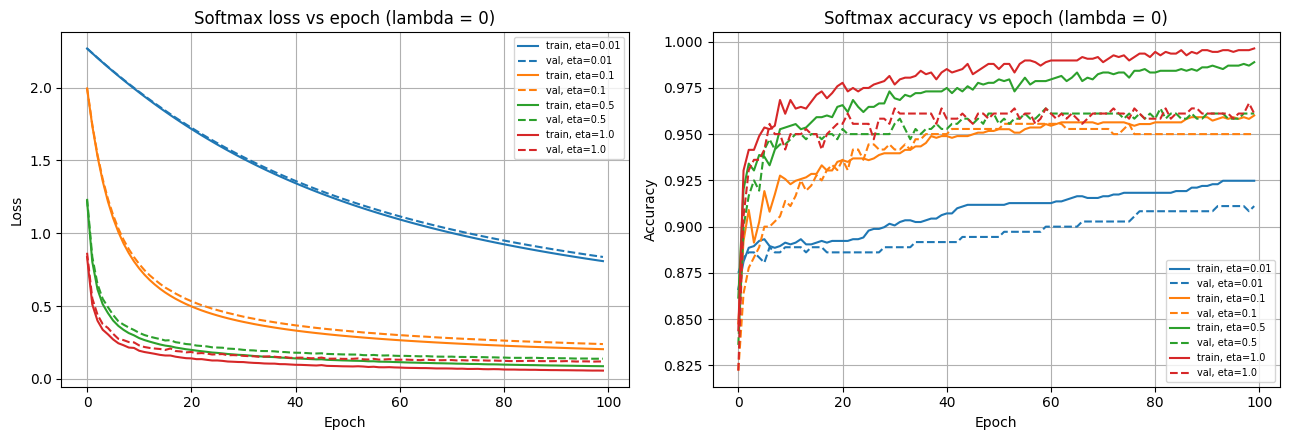

,Train loss,Train acc,Val loss,Val acc
lambda,,,,
0.0000,0.0566,0.9963,0.1193,0.9611
0.0001,0.0916,0.9963,0.1508,0.9639
0.0010,0.2580,0.9805,0.3042,0.9667
0.0100,0.7463,0.9387,0.7856,0.9278
0.1000,1.7751,0.6416,1.8035,0.6333


lambda* = 0.001   validation accuracy = 0.9667   test accuracy = 0.9528


In [35]:
# Task 18 — Softmax training and model selection (Digits, pixels / 16, no standardization)

# Add the bias column of ones to every split
def add_ones(X):
    return np.column_stack((np.ones(len(X)), X))

digits_split = splits["Digits"]
Xtr_d, Xva_d, Xte_d = (add_ones(digits_split[k]) for k in ("X_train", "X_val", "X_test"))
ytr_d, yva_d, yte_d = digits_split["y_train"], digits_split["y_val"], digits_split["y_test"]
K = 10                                                   # number of classes


def softmax_loss_grad(X, y, W, lam):
    """Cross-entropy (via log-sum-exp) + (lam/2)*||W[1:]||^2, and its gradient. The bias row is not regularized."""
    N = len(X)
    scores = X @ W
    row_max = scores.max(axis=1, keepdims=True)
    log_sum_exp = np.log(np.exp(scores - row_max).sum(axis=1, keepdims=True)) + row_max
    probs = np.exp(scores - log_sum_exp)                 # stable softmax

    data_loss = np.mean(log_sum_exp[:, 0] - scores[np.arange(N), y])
    loss = data_loss + lam / 2 * np.sum(W[1:] ** 2)

    P_minus_Y = probs.copy()
    P_minus_Y[np.arange(N), y] -= 1                      # P - one_hot(y)
    grad = X.T @ P_minus_Y / N
    grad[1:] += lam * W[1:]
    return loss, grad


def evaluate(loss_grad, X, y, W, lam):
    """Returns (loss, accuracy)."""
    loss, _ = loss_grad(X, y, W, lam)
    accuracy = np.mean(np.argmax(X @ W, axis=1) == y)
    return loss, accuracy


def train_minibatch(loss_grad, eta, lam, epochs=100, batch_size=64):
    """Mini-batch gradient descent. Returns the weights and a history array with the columns
    [train loss, train accuracy, validation loss, validation accuracy], one row per epoch."""
    rng = np.random.default_rng(42)
    W = np.zeros((Xtr_d.shape[1], K))
    history = []
    for _ in range(epochs):
        order = rng.permutation(len(Xtr_d))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            _, grad = loss_grad(Xtr_d[batch], ytr_d[batch], W, lam)
            W -= eta * grad
        history.append([*evaluate(loss_grad, Xtr_d, ytr_d, W, lam),
                        *evaluate(loss_grad, Xva_d, yva_d, W, lam)])
    return W, np.array(history)


COLUMNS = ["Train loss", "Train acc", "Val loss", "Val acc"]

# ---- (a) learning rate, lambda = 0 ----
etas = [0.01, 0.1, 0.5, 1.0]
runs_eta = {eta: train_minibatch(softmax_loss_grad, eta, lam=0) for eta in etas}

table_eta = pd.DataFrame({eta: hist[-1] for eta, (_, hist) in runs_eta.items()}, index=COLUMNS).T
table_eta.index.name = "eta"
display(table_eta.round(4))
eta_star = table_eta["Val loss"].idxmin()                # lowest final validation loss
print("eta* =", eta_star)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
for eta, (_, hist) in runs_eta.items():
    line, = ax_loss.plot(hist[:, 0], label=f"train, eta={eta}")
    ax_loss.plot(hist[:, 2], "--", color=line.get_color(), label=f"val, eta={eta}")
    ax_acc.plot(hist[:, 1], color=line.get_color(), label=f"train, eta={eta}")
    ax_acc.plot(hist[:, 3], "--", color=line.get_color(), label=f"val, eta={eta}")
for ax, name in [(ax_loss, "Loss"), (ax_acc, "Accuracy")]:
    ax.set(title=f"Softmax {name.lower()} vs epoch (lambda = 0)", xlabel="Epoch", ylabel=name)
    ax.legend(fontsize=7)
    ax.grid(True)
plt.tight_layout()
plt.show()

# (b) regularization strength, using eta*
lambdas = [0, 1e-4, 1e-3, 1e-2, 1e-1]
runs_lam = {lam: train_minibatch(softmax_loss_grad, eta_star, lam) for lam in lambdas}

table_lam = pd.DataFrame({lam: hist[-1] for lam, (_, hist) in runs_lam.items()}, index=COLUMNS).T
table_lam.index.name = "lambda"
display(table_lam.round(4))

# best validation accuracy; ties go to the larger lambda
lam_star = max(lambdas, key=lambda lam: (round(table_lam.loc[lam, "Val acc"], 12), lam))
W_softmax = runs_lam[lam_star][0]
test_acc = evaluate(softmax_loss_grad, Xte_d, yte_d, W_softmax, lam_star)[1]     # test set used once
print(f"lambda* = {lam_star}   validation accuracy = {table_lam.loc[lam_star, 'Val acc']:.4f}   test accuracy = {test_acc:.4f}")

softmax_results = {"val_accuracy": table_lam.loc[lam_star, "Val acc"], "test_accuracy": test_acc}   # used in Task 25

## Part E — Support Vector Machines (SVMs)

In this part, we will study Support Vector Machines and understand how they work for classification problems.

We will:
- Implement a Linear SVM from scratch using NumPy and understand the hinge loss and its subgradient.
- Compare our implementation with Scikit-learn's SVC and LinearSVC.
- Study how the regularization parameter (C) affects the margin, training accuracy, and support vectors.
- Explore different kernels, including Linear, Polynomial, and RBF.
- Investigate how the gamma parameter affects the decision boundary and model performance.
- Use Grid Search with cross-validation to find the best C and gamma values for the Digits dataset.

Gradient check relative error: 1.59e-10   passed: True
constant eta = 0.1   final objective 0.06054   final validation accuracy 0.9737
constant eta = 1.0   final objective 0.06096   final validation accuracy 0.9737
eta_t = 1/sqrt(t)    final objective 0.06080   final validation accuracy 0.9737


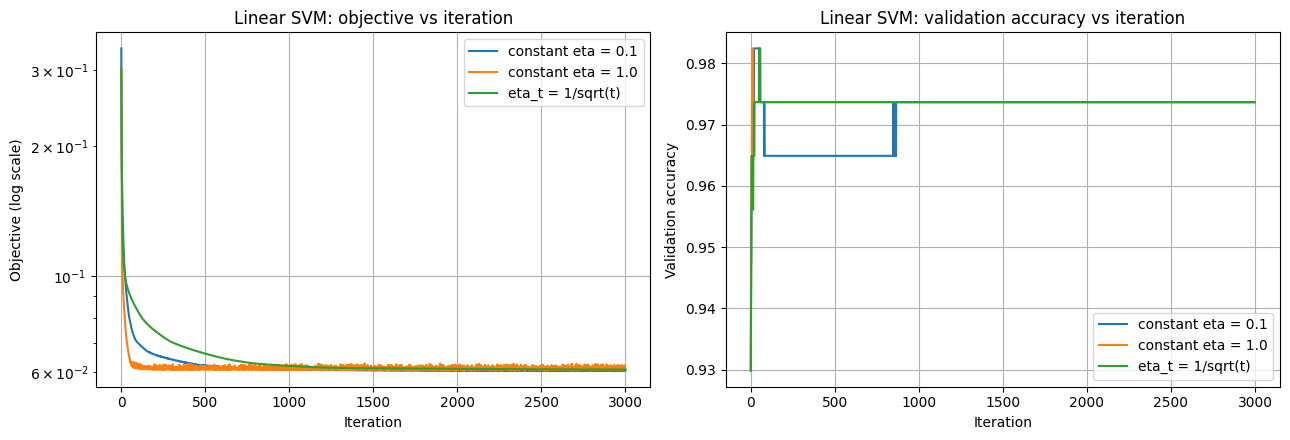

In [36]:
# Task 23 — Linear SVM from scratch (Breast Cancer, standardized, labels in {-1, +1}, lambda = 0.01)
bc = splits["Breast cancer"]
svm_mean, svm_std = bc["X_train"].mean(axis=0), bc["X_train"].std(axis=0)       # training statistics only
X_tr, X_va = ((bc[k] - svm_mean) / svm_std for k in ("X_train", "X_val"))
y_tr, y_va = 2 * bc["y_train"] - 1, 2 * bc["y_val"] - 1
LAM = 0.01


def svm_objective(X, y, w, b, lam=LAM):
    """(lam/2)||w||^2 + mean hinge loss (b is not regularized)."""
    hinge = np.maximum(0, 1 - y * (X @ w + b))
    return lam / 2 * np.sum(w ** 2) + hinge.mean()


def svm_gradient(X, y, w, b, lam=LAM):
    """Subgradient: only points with y*f(x) < 1 contribute."""
    active = y * (X @ w + b) < 1
    dw = lam * w - X[active].T @ y[active] / len(X)
    db = -y[active].sum() / len(X)
    return dw, db


# ---- Gradient check at a random point (epsilon = 1e-6, tolerance 1e-5), reusing grad_check from Task 4 ----
theta = np.random.default_rng(42).normal(0, 0.1, X_tr.shape[1] + 1)             # theta = [w, b]
objective = lambda th: svm_objective(X_tr, y_tr, th[:-1], th[-1])
subgradient = lambda th: np.append(*svm_gradient(X_tr, y_tr, th[:-1], th[-1]))
error = grad_check(objective, subgradient, theta, epsilon=1e-6)
print(f"Gradient check relative error: {error:.2e}   passed: {error < 1e-5}")

# ---- Full-batch subgradient descent, 3000 iterations, three step-size schedules ----
schedules = {
    "constant eta = 0.1": lambda t: 0.1,
    "constant eta = 1.0": lambda t: 1.0,
    "eta_t = 1/sqrt(t)":  lambda t: 1.0 / np.sqrt(t),
}

history = {}
for name, eta in schedules.items():
    w, b = np.zeros(X_tr.shape[1]), 0.0
    objectives, val_accuracies = [], []
    for t in range(1, 3001):
        dw, db = svm_gradient(X_tr, y_tr, w, b)
        w -= eta(t) * dw
        b -= eta(t) * db
        objectives.append(svm_objective(X_tr, y_tr, w, b))
        val_accuracies.append(np.mean(np.where(X_va @ w + b >= 0, 1, -1) == y_va))
    history[name] = (objectives, val_accuracies)
    print(f"{name:20s} final objective {objectives[-1]:.5f}   final validation accuracy {val_accuracies[-1]:.4f}")

fig, (ax_obj, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (objectives, val_accuracies) in history.items():
    ax_obj.plot(objectives, label=name)
    ax_acc.plot(val_accuracies, label=name)
ax_obj.set(title="Linear SVM: objective vs iteration", xlabel="Iteration", ylabel="Objective (log scale)", yscale="log")
ax_acc.set(title="Linear SVM: validation accuracy vs iteration", xlabel="Iteration", ylabel="Validation accuracy")
for ax in (ax_obj, ax_acc):
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

In [37]:
# Task 24 — Our linear SVM vs scikit-learn (reuses svm_objective, svm_gradient and svm_scaler from Task 23)
from sklearn.svm import SVC, LinearSVC

bc = splits["Breast cancer"]
X_tr, X_va, X_te = (svm_scaler.transform(bc[k]) for k in ("X_train", "X_val", "X_test"))
y_tr, y_va = 2 * bc["y_train"] - 1, 2 * bc["y_val"] - 1          # labels in {-1, +1}
N_tr = len(X_tr)


def fit_svm(lam, iters=20000):
    """Full-batch subgradient descent with step size 1/sqrt(t)."""
    w, b = np.zeros(X_tr.shape[1]), 0.0
    for t in range(1, iters + 1):
        dw, db = svm_gradient(X_tr, y_tr, w, b, lam)
        w -= dw / np.sqrt(t)
        b -= db / np.sqrt(t)
    return w, b


def margin_width(w):
    return 2 / np.linalg.norm(w)


def count_margin_points(w, b):
    """Number of training points with y*f(x) <= 1."""
    return int(np.sum(y_tr * (X_tr @ w + b) <= 1))


def val_accuracy(w, b):
    return np.mean(np.where(X_va @ w + b >= 0, 1, -1) == y_va)


# (a) detailed comparison at lambda = 0.01
lam = 0.01
w_own, b_own = fit_svm(lam)
svc = SVC(kernel="linear", C=1 / (lam * N_tr)).fit(X_tr, y_tr)
w_svc, b_svc = svc.coef_[0], svc.intercept_[0]

obj_own = svm_objective(X_tr, y_tr, w_own, b_own, lam)
obj_svc = svm_objective(X_tr, y_tr, w_svc, b_svc, lam)
cosine = w_own @ w_svc / (np.linalg.norm(w_own) * np.linalg.norm(w_svc))
agreement = np.mean(np.where(X_te @ w_own + b_own >= 0, 1, -1) == svc.predict(X_te))
n_own, n_svc = count_margin_points(w_own, b_own), svc.n_support_.sum()

print(f"Objective        ours {obj_own:.5f}   SVC {obj_svc:.5f}   relative difference {abs(obj_own - obj_svc) / obj_svc:.2e}  (need < 1e-3)")
print(f"Cosine similarity of weights: {cosine:.5f}  (need >= 0.99)")
print(f"Test prediction agreement   : {agreement:.2%}  (need >= 98%)")
print(f"Margin width     ours {margin_width(w_own):.4f}   SVC {margin_width(w_svc):.4f}")
print(f"Points with y f(x) <= 1: ours {n_own}   SVC n_support_: {n_svc}   difference {abs(n_own - n_svc)}  (need <= 5)")

# (b) sweep over lambda
rows = []
for lam in [1e-4, 1e-3, 1e-2, 1e-1, 1]:
    C = 1 / (lam * N_tr)
    w, b = fit_svm(lam)
    svc = SVC(kernel="linear", C=C).fit(X_tr, y_tr)
    lin = LinearSVC(loss="hinge", C=C, max_iter=200000, tol=1e-8, random_state=42).fit(X_tr, y_tr)
    w_lin, b_lin = lin.coef_[0], lin.intercept_[0]

    rows += [
        {"lambda": lam, "Model": "Ours",      "Val acc": val_accuracy(w, b),
         "Margin width": margin_width(w), "# support": count_margin_points(w, b)},
        {"lambda": lam, "Model": "SVC",       "Val acc": svc.score(X_va, y_va),
         "Margin width": margin_width(svc.coef_[0]), "# support": svc.n_support_.sum()},
        {"lambda": lam, "Model": "LinearSVC", "Val acc": val_accuracy(w_lin, b_lin),
         "Margin width": margin_width(w_lin), "# support": count_margin_points(w_lin, b_lin)},   # no n_support_
    ]
sweep = pd.DataFrame(rows).pivot(index="lambda", columns="Model").swaplevel(axis=1).sort_index(axis=1)
display(sweep.round(4))

Objective        ours 0.06045   SVC 0.06044   relative difference 2.02e-04  (need < 1e-3)
Cosine similarity of weights: 0.99969  (need >= 0.99)
Test prediction agreement   : 100.00%  (need >= 98%)
Margin width     ours 1.1318   SVC 1.1291
Points with y f(x) <= 1: ours 28   SVC n_support_: 32   difference 4  (need <= 5)


Model  LinearSVC                           Ours                       \
       # support Margin width Val acc # support Margin width Val acc   
lambda                                                                 
0.0001        13       0.1460  0.9474        15       0.5923  0.9649   
0.0010        22       0.4634  0.9649        17       0.6539  0.9737   
0.0100        27       1.1235  0.9737        28       1.1318  0.9737   
0.1000        57       2.1641  0.9737        56       2.1688  0.9825   
1.0000       137       4.4580  0.9649       122       4.7117  0.9649   

Model        SVC                       
       # support Margin width Val acc  
lambda                                 
0.0001        22       0.1460  0.9474  
0.0010        28       0.4620  0.9649  
0.0100        32       1.1291  0.9737  
0.1000        61       2.1688  0.9825  
1.0000       125       4.7119  0.9649

In [38]:
# Task 25 — Multiclass hinge vs softmax (reuses the Task 18 data and training loop)

def hinge_loss_grad(X, y, W, lam, delta=1.0):
    N = len(X)
    scores = X @ W
    true_scores = scores[np.arange(N), y][:, None]
    margins = scores - true_scores + delta               # s_j - s_y + delta
    margins[np.arange(N), y] = 0                         # the true class does not contribute

    loss = np.maximum(margins, 0).sum() / N + lam / 2 * np.sum(W[1:] ** 2)

    B = (margins > 0).astype(float)                      # B[i, j] = 1 for violated classes j != y
    B[np.arange(N), y] = -B.sum(axis=1)                  # B[i, y] = -(number of violations)
    grad = X.T @ B / N
    grad[1:] += lam * W[1:]
    return loss, grad


# Verification 1: loss at W = 0 must be delta * (K - 1) = 9
D = Xtr_d.shape[1]
print("Loss at W = 0:", hinge_loss_grad(Xtr_d, ytr_d, np.zeros((D, K)), lam=0)[0], "(expected 9)")

# Verification 2: gradient check on 100 random entries of W (lambda = 0.1)
rng = np.random.default_rng(0)
W_check = rng.normal(0, 0.01, (D, K))
X_check, y_check, lam_check, eps = Xtr_d[:200], ytr_d[:200], 0.1, 1e-6
analytic_grad = hinge_loss_grad(X_check, y_check, W_check, lam_check)[1]

numeric, analytic = [], []
for i, j in zip(rng.integers(0, D, 100), rng.integers(0, K, 100)):
    W_plus, W_minus = W_check.copy(), W_check.copy()
    W_plus[i, j] += eps
    W_minus[i, j] -= eps
    loss_plus = hinge_loss_grad(X_check, y_check, W_plus, lam_check)[0]
    loss_minus = hinge_loss_grad(X_check, y_check, W_minus, lam_check)[0]
    numeric.append((loss_plus - loss_minus) / (2 * eps))
    analytic.append(analytic_grad[i, j])
numeric, analytic = np.array(numeric), np.array(analytic)
rel_error = np.linalg.norm(numeric - analytic) / max(np.linalg.norm(numeric), np.linalg.norm(analytic))
print("Gradient check relative error:", rel_error, "(need < 1e-5)")

# Training exactly as in Task 18
runs_eta_h = {eta: train_minibatch(hinge_loss_grad, eta, lam=0) for eta in [0.01, 0.1, 0.5]}
eta_h = min(runs_eta_h, key=lambda eta: runs_eta_h[eta][1][-1, 2])                 # lowest final validation loss

runs_lam_h = {lam: train_minibatch(hinge_loss_grad, eta_h, lam) for lam in [0, 1e-4, 1e-3, 1e-2]}
lam_h = max(runs_lam_h, key=lambda lam: (round(runs_lam_h[lam][1][-1, 3], 12), lam))   # best val acc, ties -> larger
W_hinge, hist_hinge = runs_lam_h[lam_h]
print(f"Multiclass SVM: eta* = {eta_h}, lambda* = {lam_h}")

display(pd.DataFrame({
    "Model": ["Softmax", "Multiclass SVM"],
    "Validation accuracy": [softmax_results["val_accuracy"], hist_hinge[-1, 3]],
    "Test accuracy": [softmax_results["test_accuracy"], evaluate(hinge_loss_grad, Xte_d, yte_d, W_hinge, lam_h)[1]],
}).round(4))

# Toy analysis: true class is 0
def toy_svm_loss(s):
    return np.maximum(0, s[1:] - s[0] + 1).sum()

def toy_softmax_loss(s):
    return np.log(np.exp(s - s.max()).sum()) + s.max() - s[0]

toy_scores = [np.array(s, dtype=float) for s in ([10, -5, -5], [100, -50, -50], [3.2, 5.1, -1.7])]
display(pd.DataFrame({
    "Scores": [list(s) for s in toy_scores],
    "SVM loss": [toy_svm_loss(s) for s in toy_scores],
    "Softmax loss": [toy_softmax_loss(s) for s in toy_scores],
}, index=["a", "b", "c"]))

Loss at W = 0: 9.0 (expected 9)
Gradient check relative error: 2.8296391679783458e-09 (need < 1e-5)
Multiclass SVM: eta* = 0.5, lambda* = 0.001


,Model,Validation accuracy,Test accuracy
0,Softmax,0.9667,0.9528
1,Multiclass SVM,0.9694,0.9500


,Scores,SVM loss,Softmax loss
a,"[10.0, -5.0, -5.0]",0.0,6.118045e-07
b,"[100.0, -50.0, -50.0]",0.0,0.000000e+00
c,"[3.2, 5.1, -1.7]",2.9,2.040355e+00


In [39]:
# Task 26 — Kernels and C
from sklearn.svm import SVC

bc = splits["Breast cancer"]
mean, std = bc["X_train"].mean(axis=0), bc["X_train"].std(axis=0)
Z_tr, Z_va, Z_te = ((bc[k] - mean) / std for k in ("X_train", "X_val", "X_test"))
y_tr, y_va, y_te = bc["y_train"], bc["y_val"], bc["y_test"]

# (a) three kernels, C = 1
kernels = {
    "Linear":     SVC(kernel="linear", C=1),
    "Polynomial": SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1),
    "RBF":        SVC(kernel="rbf", gamma="scale", C=1),
}
rows = []
for name, model in kernels.items():
    model.fit(Z_tr, y_tr)
    rows.append({"Kernel": name, "Train acc": model.score(Z_tr, y_tr), "Val acc": model.score(Z_va, y_va),
                 "Test acc": model.score(Z_te, y_te), "# SV": model.n_support_.sum()})
display(pd.DataFrame(rows).round(4))

# (b) linear SVC for several C
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=C).fit(Z_tr, y_tr)
    rows.append({"C": C, "Train acc": model.score(Z_tr, y_tr), "Val acc": model.score(Z_va, y_va),
                 "# SV": model.n_support_.sum(), "Margin width": 2 / np.linalg.norm(model.coef_)})
display(pd.DataFrame(rows).round(4))

,Kernel,Train acc,Val acc,Test acc,# SV
0,Linear,0.9883,0.9649,0.9298,30
1,Polynomial,0.9912,0.9825,0.9737,52
2,RBF,0.9824,0.9825,0.9737,88


,C,Train acc,Val acc,# SV,Margin width
0,0.001,0.9326,0.9561,175,6.7619
1,0.010,0.9736,0.9737,83,3.1690
2,0.100,0.9795,0.9649,43,1.5669
3,1.000,0.9883,0.9649,30,0.6727
4,10.000,0.9971,0.9386,23,0.2471
5,100.000,1.0000,0.9474,22,0.1460


,gamma,Train acc,Val acc,# SV
0,0.01,0.8827,0.8684,166
1,0.10,0.9003,0.8947,109
2,1.00,0.9120,0.8947,108
3,10.00,0.9296,0.8772,201
4,100.00,0.9824,0.7368,311


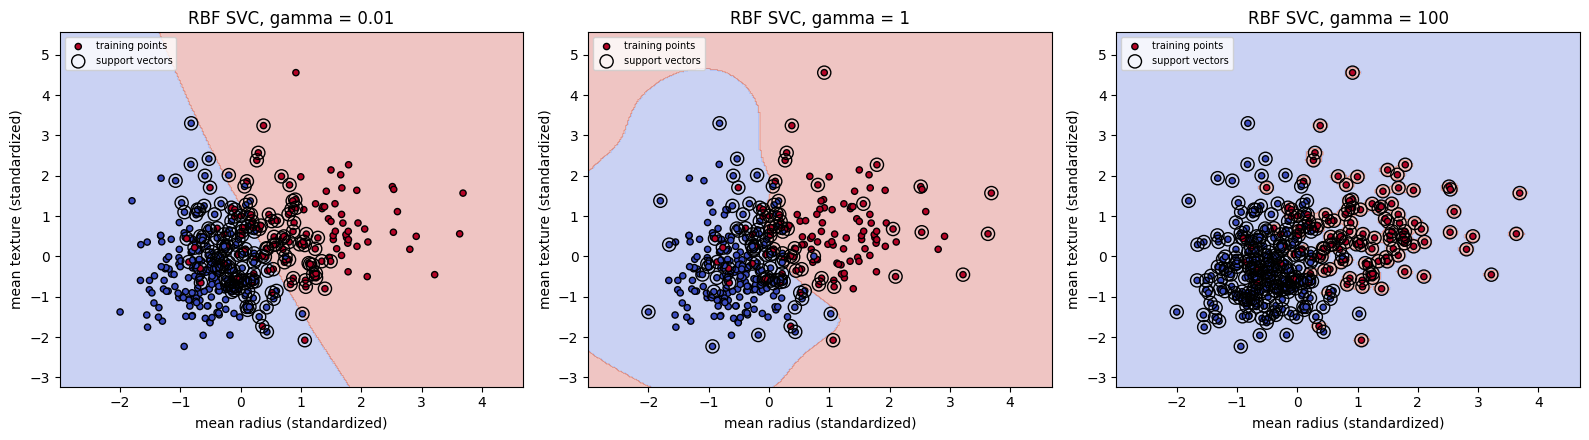

In [40]:
# Task 27 — Effect of gamma
from sklearn.svm import SVC

bc = splits["Breast cancer"]
cols = [list(bc["feature_names"]).index(name) for name in ("mean radius", "mean texture")]
P_tr, P_va = bc["X_train"][:, cols], bc["X_val"][:, cols]
mean, std = P_tr.mean(axis=0), P_tr.std(axis=0)
P_tr, P_va = (P_tr - mean) / std, (P_va - mean) / std
y_tr, y_va = bc["y_train"], bc["y_val"]

gammas = [0.01, 0.1, 1, 10, 100]
models = {g: SVC(kernel="rbf", C=1, gamma=g).fit(P_tr, y_tr) for g in gammas}
display(pd.DataFrame([{"gamma": g, "Train acc": m.score(P_tr, y_tr), "Val acc": m.score(P_va, y_va),
                       "# SV": m.n_support_.sum()} for g, m in models.items()]).round(4))

# Decision regions for three gammas, support vectors circled
xx, yy = np.meshgrid(np.linspace(P_tr[:, 0].min() - 1, P_tr[:, 0].max() + 1, 300),
                     np.linspace(P_tr[:, 1].min() - 1, P_tr[:, 1].max() + 1, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, g in zip(axes, [0.01, 1, 100]):
    model = models[g]
    ax.contourf(xx, yy, model.predict(grid).reshape(xx.shape), alpha=0.3, cmap="coolwarm")
    ax.scatter(P_tr[:, 0], P_tr[:, 1], c=y_tr, cmap="coolwarm", edgecolors="k", s=20, label="training points")
    ax.scatter(*model.support_vectors_.T, facecolors="none", edgecolors="k", s=90, label="support vectors")
    ax.set(title=f"RBF SVC, gamma = {g}", xlabel="mean radius (standardized)", ylabel="mean texture (standardized)")
    ax.legend(loc="upper left", fontsize=7)
plt.tight_layout()
plt.show()

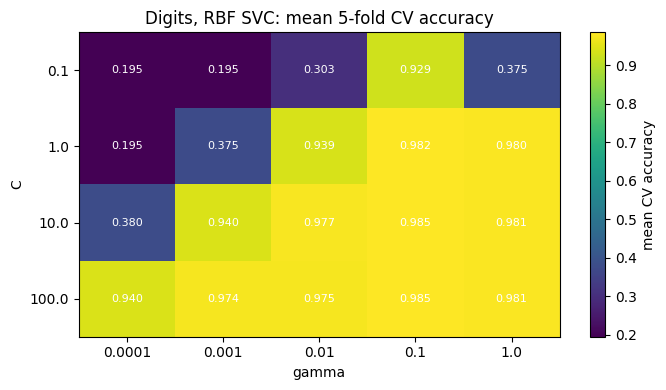

Best parameters: {'C': 10, 'gamma': 0.1}    best CV accuracy: 0.9851
Test accuracy (used once): 0.9917


In [41]:
# Task 28 — GridSearchCV for an RBF SVC on Digits (pixels / 16; `splits` already stores them divided by 16)
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold

X_tr, y_tr = splits["Digits"]["X_train"], splits["Digits"]["y_train"]
X_te, y_te = splits["Digits"]["X_test"], splits["Digits"]["y_test"]

param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=cv).fit(X_tr, y_tr)

# Heat map of the mean CV accuracy (rows = C, columns = gamma)
cv_acc = pd.DataFrame(grid.cv_results_).pivot(index="param_C", columns="param_gamma", values="mean_test_score")
plt.figure(figsize=(7, 4))
plt.imshow(cv_acc.values, cmap="viridis", aspect="auto")
plt.colorbar(label="mean CV accuracy")
plt.xticks(range(len(cv_acc.columns)), cv_acc.columns)
plt.yticks(range(len(cv_acc.index)), cv_acc.index)
for (i, j), value in np.ndenumerate(cv_acc.values):
    plt.text(j, i, f"{value:.3f}", ha="center", va="center", color="white", fontsize=8)
plt.xlabel("gamma")
plt.ylabel("C")
plt.title("Digits, RBF SVC: mean 5-fold CV accuracy")
plt.tight_layout()
plt.show()

print("Best parameters:", grid.best_params_, "   best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy (used once):", round(grid.score(X_te, y_te), 4))

## Part F — Comparison and Synthesis

In this part, we will connect the concepts learned throughout the assignment and compare the different machine learning models.

We will:
- Compare Linear Regression, Logistic Regression, Softmax, and SVM in terms of their loss functions, gradients, and output meanings.
- Understand the differences between probability predictions and decision margins.
- Discuss when each model is appropriate and how different loss functions handle misclassified samples and outliers.
- Compare the computational costs of linear models and Kernel SVM.
- Summarize the main findings and lessons learned from the experiments.

**The main goal of these two parts** is to understand how SVMs work, how their parameters affect performance, and how they compare with the other machine learning models studied in this assignment.


| Model | Per-sample loss L(s, y) | Gradient ∂L/∂s | Output meaning |
|---|---|---|---|
| Linear Regression | ½(s − y)² | s − y | A continuous numerical prediction |
| Logistic Regression | −[y log(σ(s)) + (1−y) log(1−σ(s))] | σ(s) − y | Probability of the positive class |
| Softmax Classifier | −log(p_y), where p_j = exp(s_j) / Σ exp(s_k) | p − e_y | Probabilities for all classes |
| Binary / Multiclass SVM | Binary: max(0, 1 − ys). Multiclass: Σ(j≠y) max(0, s_j − s_y + 1) | Binary: −y if ys < 1, otherwise 0. Multiclass: B, as defined in Task 25 | Decision scores and margins, not probabilities |



## Conclusions

**(a) When would you choose each model?**

- Ridge Regression is suitable for predicting continuous values, especially when features are correlated. Regularization helps reduce overfitting.
- Logistic Regression is a good choice for binary classification when we need probability estimates.
- Softmax is suitable for multiclass classification when we need probabilities for all classes.
- Linear SVM works well for classification problems where a linear decision boundary is suitable and a clear margin is important.
- Kernel SVM is useful when the data has nonlinear decision boundaries. It can handle more complex patterns using kernels such as RBF and polynomial.

**(b) Probabilities vs. margins**

Logistic Regression and Softmax produce probability estimates. However, these probabilities are not necessarily calibrated. Linear SVM and Kernel SVM produce decision scores or margins, not probabilities. Linear Regression produces numerical predictions rather than class probabilities.

**(c) How do the losses treat badly misclassified outliers?**

Squared loss increases quadratically with the prediction error, so large errors have a strong effect. Logistic loss increases approximately linearly for very confident wrong predictions. Hinge loss also increases linearly when the margin is violated, so its penalty does not grow quadratically.

**(d) Training and prediction costs**

For linear models, one training epoch generally costs O(Nd), while predicting one sample costs O(d). Kernel SVMs can require much more training time and memory because they depend on relationships between training samples. Prediction also becomes more expensive as the number of support vectors increases.

**(e) What surprised me most?**

I was surprised by how strongly the SVM parameters affect the decision boundary. In Task 27, gamma = 100 achieved 98.24% training accuracy but only 73.68% validation accuracy, showing clear overfitting. In Task 28, Grid Search achieved 97.59% cross-validation accuracy and 97.78% test accuracy. I also found that the multiclass SVM and Softmax achieved very similar results on Digits, with 95.00% and 95.28% test accuracy, respectively.





### Bonus 1: Simplified SMO Algorithm for RBF SVM

In this bonus, we will implement a simplified Sequential Minimal Optimization (SMO) algorithm to train an RBF Kernel Support Vector Machine from scratch.

We will:
- Use two features from the Breast Cancer dataset: `mean radius` and `mean texture`.
- Standardize the features using the training data.
- Train an RBF SVM using SMO with C = 1 and gamma = 1.
- Apply the KKT conditions and update pairs of Lagrange multipliers.
- Check the learned multipliers and compare our model with Scikit-learn.

The goal is to understand how SMO trains an SVM and compare our implementation with an existing library.

In [42]:
# Bonus 1 — Simplified SMO for an RBF SVM (mean radius and mean texture, C = 1, gamma = 1)
from sklearn.svm import SVC

bc = splits["Breast cancer"]
cols = [list(bc["feature_names"]).index(name) for name in ("mean radius", "mean texture")]
Q_tr, Q_te = bc["X_train"][:, cols], bc["X_test"][:, cols]
mean, std = Q_tr.mean(axis=0), Q_tr.std(axis=0)
Q_tr, Q_te = (Q_tr - mean) / std, (Q_te - mean) / std
y_q = 2 * bc["y_train"] - 1                                          # labels in {-1, +1}


def rbf_kernel(A, B, gamma=1.0):
    sq_dist = (A ** 2).sum(axis=1)[:, None] + (B ** 2).sum(axis=1)[None, :] - 2 * A @ B.T
    return np.exp(-gamma * sq_dist)


def simplified_smo(X, y, C=1.0, gamma=1.0, tol=1e-3, max_passes=20):
    n = len(X)
    rng = np.random.default_rng(42)
    K = rbf_kernel(X, X, gamma)
    alpha, b = np.zeros(n), 0.0
    f = lambda k: (alpha * y) @ K[:, k] + b                         # decision value of training point k

    passes = 0                                                      # consecutive passes without any change
    while passes < max_passes:
        changed = 0
        for i in range(n):
            Ei = f(i) - y[i]
            violates_kkt = (y[i] * Ei < -tol and alpha[i] < C) or (y[i] * Ei > tol and alpha[i] > 0)
            if not violates_kkt:
                continue

            j = rng.choice(np.delete(np.arange(n), i))              # random partner j != i
            Ej = f(j) - y[j]
            ai_old, aj_old = alpha[i], alpha[j]

            # Box limits L, H for the new alpha_j
            if y[i] != y[j]:
                L, H = max(0, aj_old - ai_old), min(C, C + aj_old - ai_old)
            else:
                L, H = max(0, ai_old + aj_old - C), min(C, ai_old + aj_old)
            eta = 2 * K[i, j] - K[i, i] - K[j, j]
            if L == H or eta >= 0:
                continue

            # Closed-form solution of the two-variable problem, clipped to the box
            alpha[j] = np.clip(aj_old - y[j] * (Ei - Ej) / eta, L, H)
            if abs(alpha[j] - aj_old) < 1e-5:
                alpha[j] = aj_old
                continue
            alpha[i] = ai_old + y[i] * y[j] * (aj_old - alpha[j])

            # Update the bias
            b1 = b - Ei - y[i] * (alpha[i] - ai_old) * K[i, i] - y[j] * (alpha[j] - aj_old) * K[i, j]
            b2 = b - Ej - y[i] * (alpha[i] - ai_old) * K[i, j] - y[j] * (alpha[j] - aj_old) * K[j, j]
            if 0 < alpha[i] < C:
                b = b1
            elif 0 < alpha[j] < C:
                b = b2
            else:
                b = (b1 + b2) / 2
            changed += 1

        passes = passes + 1 if changed == 0 else 0
    return alpha, b


alpha, b = simplified_smo(Q_tr, y_q)

# SMO constraint checks
equality_value = alpha @ y_q
print("SMO Constraint Checks:")
print("Minimum alpha:", alpha.min())
print("Maximum alpha:", alpha.max())
print("Sum(alpha * y):", equality_value)
print("Alpha bounds satisfied:", alpha.min() >= -1e-6 and alpha.max() <= 1 + 1e-6)
print("Equality constraint satisfied:", abs(equality_value) < 1e-6)

# Comparison with scikit-learn
our_pred = np.where(rbf_kernel(Q_te, Q_tr) @ (alpha * y_q) + b >= 0, 1, -1)
reference = SVC(kernel="rbf", C=1, gamma=1).fit(Q_tr, y_q)
agreement = np.mean(our_pred == reference.predict(Q_te)) * 100

print("\nSMO vs Scikit-learn:")
print("Test prediction agreement:", round(agreement, 2), "%")
print("Our support vectors:", int(np.sum(alpha > 1e-5)))
print("Scikit-learn support vectors:", reference.n_support_.sum())

SMO Constraint Checks:
Minimum alpha: -5.551115123125783e-17
Maximum alpha: 1.0
Sum(alpha * y): 9.992007221626409e-16
Alpha bounds satisfied: True
Equality constraint satisfied: True

SMO vs Scikit-learn:
Test prediction agreement: 100.0 %
Our support vectors: 109
Scikit-learn support vectors: 108


### Bonus 2: Logistic Regression with Class Imbalance

In this bonus, we will investigate the effect of class imbalance on Logistic Regression using the Breast Cancer dataset.

We will:
- Create an imbalanced training dataset by keeping all benign samples and randomly selecting only 15% of malignant samples.
- Train Logistic Regression using Gradient Descent with and without class weights.
- Use the original test set to evaluate both models.
- Compare Accuracy, Precision, Recall, and Average Precision.
- Plot Precision-Recall curves to visualize the performance of both models.

The goal is to understand how class weighting affects the model's ability to identify minority-class samples and why accuracy alone may not be sufficient for evaluating imbalanced datasets.


Imbalanced training set: benign = 214  malignant = 19


,Precision,Recall,Accuracy
Unweighted,1.0,0.8810,0.9561
Class-weighted,1.0,0.9524,0.9825


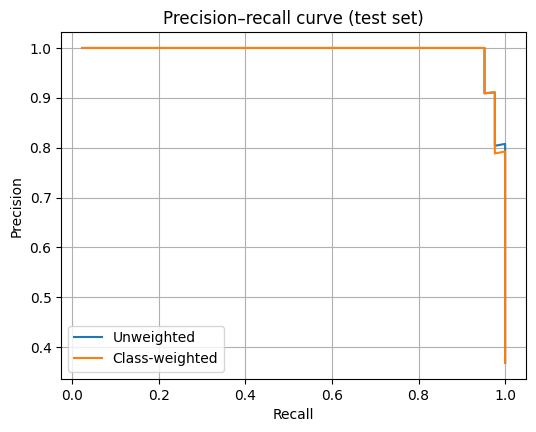

In [43]:
# Bonus 2 — Logistic regression with class imbalance (malignant = 1)
bc = splits["Breast cancer"]

# Keep every benign row and a random 15% of the malignant rows
rng = np.random.default_rng(0)
malignant = np.where(bc["y_train"] == 1)[0]
benign = np.where(bc["y_train"] == 0)[0]
kept = np.concatenate([benign, rng.choice(malignant, int(0.15 * len(malignant)), replace=False)])
X_imb, y_imb = bc["X_train"][kept], bc["y_train"][kept]

mean, std = X_imb.mean(axis=0), X_imb.std(axis=0)
X_imb, X_te, y_te = (X_imb - mean) / std, (bc["X_test"] - mean) / std, bc["y_test"]
print("Imbalanced training set: benign =", (y_imb == 0).sum(), " malignant =", (y_imb == 1).sum())


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def train_logreg(X, y, sample_weight, lam=0.01, eta=0.1, epochs=3000):
    """Full-batch GD on the weighted mean log-loss + (lam/2)||w||^2 (bias not regularized)."""
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        residual = sample_weight * (sigmoid(X @ w + b) - y)
        w -= eta * (X.T @ residual / len(y) + lam * w)
        b -= eta * residual.mean()
    return w, b


def precision_recall(y, scores, threshold):
    predicted = scores >= threshold
    true_pos = np.sum(predicted & (y == 1))
    return true_pos / max(predicted.sum(), 1), true_pos / np.sum(y == 1)


# (i) unweighted, (ii) class weights w_c = N / (2 N_c)
class_counts = np.bincount(y_imb)
weights = {"Unweighted": np.ones(len(y_imb)),
           "Class-weighted": (len(y_imb) / (2 * class_counts))[y_imb]}

test_probs = {}
for name, sample_weight in weights.items():
    w, b = train_logreg(X_imb, y_imb, sample_weight)
    test_probs[name] = sigmoid(X_te @ w + b)

rows = {}
for name, p in test_probs.items():
    precision, recall = precision_recall(y_te, p, 0.5)
    rows[name] = {"Precision": precision, "Recall": recall, "Accuracy": np.mean((p >= 0.5) == y_te)}
display(pd.DataFrame(rows).T.round(4))

# Precision-recall curve from scratch: one point per threshold (every distinct predicted probability)
plt.figure(figsize=(6, 4.5))
for name, p in test_probs.items():
    points = np.array([precision_recall(y_te, p, t) for t in np.sort(np.unique(p))[::-1]])
    plt.plot(points[:, 1], points[:, 0], label=name)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–recall curve (test set)")
plt.legend()
plt.grid(True)
plt.show()